In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2 as cv
from PIL import Image
from sklearn.model_selection import train_test_split

import os
import gdown
import zipfile
import warnings
from pathlib import Path
from collections import Counter
from copy import deepcopy

import torch
import torch.nn as nn
from torch.nn import functional as F
from torch.utils.data import Subset
from torch.utils.data import DataLoader

import torchvision
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.transforms import v2
from torchvision.datasets import ImageFolder



warnings.filterwarnings('ignore')
RANDOM_SEED = 69
torch.manual_seed(RANDOM_SEED)


In [5]:
%%capture
%pip install gdown

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Qurilma: {device}")
print(f"Qurilma nomi: {torch.cuda.get_device_name(0)}")

Qurilma: cuda
Qurilma nomi: Tesla T4


In [7]:
# Pretrained ResNet50 yuklash

weights = ResNet50_Weights.IMAGENET1K_V2
model = resnet50(weights=weights).to(device)

for param in model.parameters():
  param.requires_grad = False

for name, param in model.named_parameters():
    print(
        name,
        "Shape:", param.shape,
        "Device:", param.device,
        "Trainable:", param.requires_grad
    )

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 156MB/s]


conv1.weight Shape: torch.Size([64, 3, 7, 7]) Device: cuda:0 Trainable: False
bn1.weight Shape: torch.Size([64]) Device: cuda:0 Trainable: False
bn1.bias Shape: torch.Size([64]) Device: cuda:0 Trainable: False
layer1.0.conv1.weight Shape: torch.Size([64, 64, 1, 1]) Device: cuda:0 Trainable: False
layer1.0.bn1.weight Shape: torch.Size([64]) Device: cuda:0 Trainable: False
layer1.0.bn1.bias Shape: torch.Size([64]) Device: cuda:0 Trainable: False
layer1.0.conv2.weight Shape: torch.Size([64, 64, 3, 3]) Device: cuda:0 Trainable: False
layer1.0.bn2.weight Shape: torch.Size([64]) Device: cuda:0 Trainable: False
layer1.0.bn2.bias Shape: torch.Size([64]) Device: cuda:0 Trainable: False
layer1.0.conv3.weight Shape: torch.Size([256, 64, 1, 1]) Device: cuda:0 Trainable: False
layer1.0.bn3.weight Shape: torch.Size([256]) Device: cuda:0 Trainable: False
layer1.0.bn3.bias Shape: torch.Size([256]) Device: cuda:0 Trainable: False
layer1.0.downsample.0.weight Shape: torch.Size([256, 64, 1, 1]) Device: c

In [8]:
# Qayta train uchun modeling FC parametrlani trainga ochamiz

model.fc = nn.Linear(in_features = model.fc.in_features, out_features = 7).to(device)

for name, fc in model.fc.named_parameters():
  print(f"Name: {name}, Shape: {fc.shape}, Device: {fc.device}, Trainable: {fc.requires_grad}")

Name: weight, Shape: torch.Size([7, 2048]), Device: cuda:0, Trainable: True
Name: bias, Shape: torch.Size([7]), Device: cuda:0, Trainable: True


In [9]:
file_id = "14CkkOGjQV17wh7x0pmc5woJU9IzRdrr9"

fayl = gdown.download(
    id=file_id,
    output="uzbek_foods.zip",
    quiet=True
)

if fayl is not None:
    print("Yuklangan fayl:", fayl)
    print("ZIP formatidami:", zipfile.is_zipfile(fayl))

Yuklangan fayl: uzbek_foods.zip
ZIP formatidami: True


## Ushbu loyiha uchun özbek taomlari tasvirlaridan iborat ma'lumotlar töplami shakllantirildi. Rasmlar veb-saytlardan **web scraping** orqali yig'ish, internetdan qölda yuklab olish hamda ochiq e'lon qilingan datasetlardan foydalanish orqali töplandi.

## Dataset **7 ta sinf va jami 7 085 ta rasmni** öz ichiga oladi. Sinflar: ``lag'mon, manti, palov, perashki, shashlik, shörva va somsa``. Rasmlar taom turiga qarab alohida papkalarga joylashtirildi.

## Ma'lumotlar töplami transfer learning yordamida öqitish va özbek taomlarini rasmlar asosida tasniflashni örganish uchun tayyorlandi.

### Datasetdan ```file_id``` orqali foydalanishingiz mumkin.

In [11]:
zpath = Path("/content/uzbek_foods.zip")
zmkdir = Path('Data')
with zipfile.ZipFile(zpath, 'r') as zopen:
  zopen.extractall(zmkdir)

In [12]:
for element in sorted(zmkdir.iterdir()):
    print(element.name, "— papka" if element.is_dir() else "— fayl")

Uzbek-Foods — papka


In [13]:
# preprocess = weights.transforms() # Tayyoridan foydalanish uchun

preprocess =  v2.Compose([
    v2.Resize(size=232, interpolation=v2.InterpolationMode.BILINEAR, antialias=True),
    v2.CenterCrop(size=224),
    v2.ToImage(),
    v2.ToDtype(dtype=torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [14]:
dataset = ImageFolder(
    root = '/content/Data/Uzbek-Foods',
    transform=preprocess)

print(f"Jami rasmlar: {len(dataset)}")
print(f"Sinflar soni: {dataset.classes}")
print(f"Sinf raqamlari: {dataset.class_to_idx}")

sonlar = Counter(dataset.targets)

for nom, raqam in dataset.class_to_idx.items():
  print(f"{raqam} — {nom}: {sonlar[raqam]} ta")

Jami rasmlar: 7048
Sinflar soni: ['Lagmon', 'Manti', 'Palov', 'Perashka', 'Shashlik', 'Shorva', 'Somsa']
Sinf raqamlari: {'Lagmon': 0, 'Manti': 1, 'Palov': 2, 'Perashka': 3, 'Shashlik': 4, 'Shorva': 5, 'Somsa': 6}
0 — Lagmon: 1116 ta
1 — Manti: 711 ta
2 — Palov: 996 ta
3 — Perashka: 1031 ta
4 — Shashlik: 1691 ta
5 — Shorva: 520 ta
6 — Somsa: 983 ta


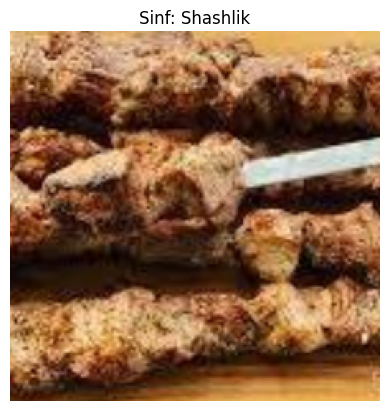

In [27]:
# Tasodifiy bitta rasm olib chizib ko'ramiz

rasm, sinf = dataset[np.random.randint(7047)]
def denormalize(tensor, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]):
    # Teskari normallashtirish: x * std + mean
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    return tensor * std + mean

# Rasmni asl holatiga qaytarib vizualizatsiya qilamiz
rasm_asl = denormalize(rasm)

plt.imshow(rasm_asl.permute(1, 2, 0).clip(0, 1).cpu().numpy())
plt.title(f"Sinf: {dataset.classes[sinf]}")
plt.axis('off')
plt.show()

In [29]:
b_idx = list(range(len(dataset)))

train_idx, val_test_idx = train_test_split(
    b_idx,
    train_size=0.70,
    stratify=dataset.targets,
    random_state=RANDOM_SEED,
    shuffle=True)

qolgan_sinflar = [dataset.targets[i] for i in val_test_idx]

val_idx, test_idx = train_test_split(
    val_test_idx,
    test_size=0.50,
    stratify=qolgan_sinflar,
    random_state=RANDOM_SEED,
    shuffle=True)

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 4933
Validation: 1057
Test: 1058


In [30]:
BATCH_SIZE = 32

train_loader = DataLoader(
    dataset = train_dataset,
    batch_size = BATCH_SIZE,
    num_workers = os.cpu_count(),
    shuffle = True
)

val_loader = DataLoader(
    dataset = val_dataset,
    batch_size = BATCH_SIZE,
    num_workers = os.cpu_count(),
    shuffle = False
)

test_loader = DataLoader(
    dataset = test_dataset,
    batch_size = BATCH_SIZE,
    num_workers = os.cpu_count(),
    shuffle = False
)

rasmlar, sinflar = next(iter(train_loader))

print(f"Rasmlar shakli: {rasmlar.shape}")
print(f"Sinflar shakli: {sinflar.shape}")

Rasmlar shakli: torch.Size([32, 3, 224, 224])
Sinflar shakli: torch.Size([32])


In [32]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr = 0.001)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer = optimizer,
    mode = 'min',
    factor = 0.5,
    patience = 2,
    min_lr = 1e-6
  )